In [ ]:
# To identify unknown internal marks with  with study hours

import numpy as np
from sklearn.linear_model import LinearRegression

X=np.array([[12],[5],[15],[4]])
y=np.array([78,45,88,39])

model = LinearRegression()

model.fit(X,y)


res=model.predict([[8]])
print(res)



[58.]


In [ ]:
# To identify unknown internal marks with  with attendance

import numpy as np
from sklearn.linear_model import LinearRegression

att=np.array([[85],[62],[91],[55]])
y=np.array([78,45,88,39])

model = LinearRegression()

model.fit(att,y)


res=model.predict([[74]])
print(res)



[63.53574363]


In [ ]:
# Now we found the unknow value using both study hours column and attendance column and found two values . Which column to choose so we use correlation

# To find the correlation for study_hours
X1=X.ravel()  # we cannot find correlation for 1d and 2d array so to convert from 2d to 1d we can use ravel
np.corrcoef(X1,y)

# To find the correlation for attendance
X2=att.ravel()
np.corrcoef(X2,y)

array([[1.       , 0.9976358],
       [0.9976358, 1.       ]])

In [ ]:
# To identify unknown internal marks with attendance and study hours

import numpy as np
from sklearn.linear_model import LinearRegression

att=np.array([[85,12],[62,5],[91,15],[55,4]])
y=np.array([78,45,88,39])

model = LinearRegression()

model.fit(att,y)


res=model.predict([[74,8]])
print(res)



[60.68350515]


https://medium.com/@rubinapaudelduhh/standardscaler-in-machine-learning-vs-z-score-in-statistics-f5babbb97455  - medium standardization


In [ ]:
# Data preprocessing
import numpy as np
import pandas as pd
from sklearn.preprocessing  import LabelEncoder,MinMaxScaler,StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import skew

# Import dataset
df=pd.read_excel(r"ML_data.xlsx",sheet_name=0)

# View and inspect
df.sample(5)
df.head()

# Split the features and target
X=df.drop("Final_Result",axis=1)
y=df["Final_Result"]

# To see the null values
df.isnull()
df.isnull().sum()

# To fill the null values
df['Internal_Marks'].fillna(df['Internal_Marks'].mean())
df['Internal_Marks']=df['Internal_Marks'].fillna(df['Internal_Marks'].mean())

# To convert categorical data to numbers
#1.label encoding - categorical data
encoder=LabelEncoder()
encoder.fit_transform(df['Gender'])
df['Gender_encoded']=encoder.fit_transform(df['Gender'])
df["Department_encoded"]=encoder.fit_transform(df['Department'])

#2. One hot encoding - more than two categories
pd.get_dummies(df,columns=['Department'])

# Scaling two methods (can use any one method)
# 1. Normalization - minmaxscaler between 0 to 1(when there are fixed values use normalization)
scaler=MinMaxScaler()
df["Study_Hours_scaled"]=scaler.fit_transform(df[["Study_Hours"]])

# 2. Standardization - using standard deviation and mean (when there are outliers use standardization)
std_scaler=StandardScaler()
df["Study_hrs_std_scaled"]=std_scaler.fit_transform(df[["Study_Hours"]])

# Training --> Testing(predicting) --> Evaluation(like giving a score , we evaluate using the metrics)



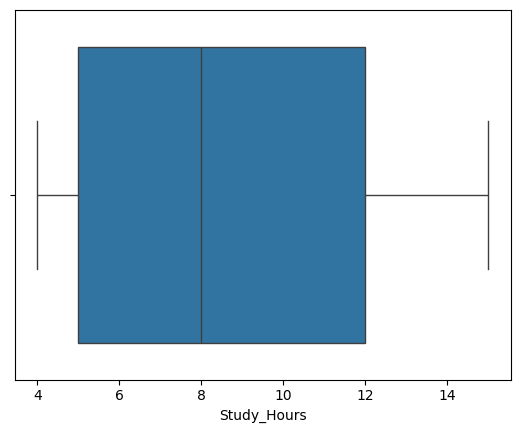

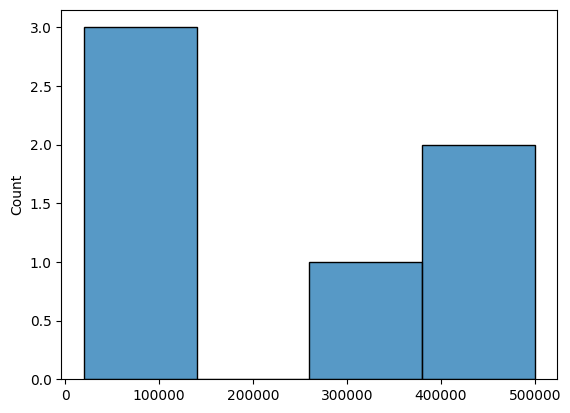

0    0.335596
dtype: float64
0    0.034374
dtype: float64


In [ ]:
# Visualization - boxplot can be used to find the outlier
sns.boxplot(x=df["Study_Hours"])
plt.show()


sns.histplot([20000, 22000, 25000, 300000, 400000, 500000])
plt.show()

# When it is skewed transform using Logarithmic method
np.log1p([20000, 22000, 25000, 300000, 400000, 500000])


# Skew     =0-Symmetric, >0 - Positive skew  , <0-Negative skew
print(pd.DataFrame([20000, 22000, 25000, 300000, 400000, 500000]).skew())

# It was +ve skewed so transform using logarithmic method to modrate the skewness
print(pd.DataFrame(np.log1p([20000, 22000, 25000, 300000, 400000, 500000])).skew())

In [ ]:
# y - actual value and dependent variable because it depends on features
# y cap - predicted value
# Error : y-y cap  . Errors is also known as resisuals

Data Processing using date time

In [ ]:
df["Adm_date"]=pd.DataFrame(['2026-01-15', '2026-02-20', '2026-03-05'])

In [ ]:
df["Adm_date"]=pd.to_datetime(df["Adm_date"])
df["Adm_date"].dtypes

#Some methods are not designed with data vectorization. So we need to apply for each. dt is an accessor from that we can access year,month
df["Adm_date"].dt.year
df["Adm_date"].dt.month

,Adm_date
0,1.0
1,2.0
2,3.0
3,NaN
4,NaN


Feature Engineering

In [ ]:
# To find Average of every student
df["Average"]=df[["Attendance","Internal_Marks"]].mean(axis=1)

# Tofind the maximum marks of each student
df["Maximum"]=df[["Attendance","Internal_Marks"]].max(axis=1)

# to sum up the marks who are fail
df["Failed_marks"]=(df[["Attendance","Internal_Marks"]]<50).sum(axis=1)
df


,Student_ID,Department,Attendance,Internal_Marks,Study_Hours,Backlogs,Gender,Final_Result,Gender_encoded,Department_encoded,Study_Hours_scaled,Study_hrs_std_scaled,Adm_date,Average,Maximum,Failed_marks
0,101,CSE,85,78.0,12,0,Female,Pass,0,0,0.727273,0.768025,2026-01-15,81.50,85.0,0
1,102,IT,62,45.0,5,2,Male,Fail,1,2,0.090909,-0.912029,2026-02-20,53.50,62.0,1
2,103,CSE,91,88.0,15,0,Female,Pass,0,0,1.000000,1.488048,2026-03-05,89.50,91.0,0
3,104,ECE,74,62.5,8,1,Male,Pass,1,1,0.363636,-0.192006,NaT,68.25,74.0,0
4,105,IT,55,39.0,4,3,Female,Fail,0,2,0.000000,-1.152037,NaT,47.00,55.0,1


Feature selection - Based on the needs choose the features that are needed

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [ ]:
data=pd.read_excel("ML_data.xlsx",sheet_name=1)

In [ ]:
df=pd.DataFrame(data)
df

In [ ]:
X=df[["Attendance","Study_Hours","Assignment_Score","Internal_Marks","Previous_GPA","Backlogs","Library_Hours"]]
y=df["Final_Score"]

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)
model=LinearRegression()
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
print(y_pred)
print(y_test)